# Settings

In [1]:
parameters_file_path = "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_rf/master_thesis/001_params_angles_ref2.json"
convert_complex = False

apply_directional_filter = False     #!convert_complex must be True for this # not really
directional_filter_direction = "up"  # up, down
apply_hp_svd = False
apply_hp = False
apply_noise_profile = False

#Simulation settings
using_simulation_data = True
rf_matrix_path = "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_rf/master_thesis/rf/001_rf_results_angles_ref2.npy"

#Real data settings
using_matlab_data = False       #! high RAM usage for big files -> convert mat file to npy for memory map usage and set using_simulation_data to False
interpolate_data = True

#Batch processing settings
batch_processing = True
batch_size = 1                 #ignored if batch_processing is False
frames_to_process = 1
MAX_WORKERS = 1                 #max is 12 for the current computer (10 max recommended)

#Saving parameters
rf_data_path = "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_rf/master_thesis/"
folder_name = "rf"
processed_rf_matrix_name = "001_rf_results_interpolated_angles_ref2"

# Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
import json
import os

import modules.preprocessing as pp

# Import parameters

In [3]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params


In [4]:
def add_extra_params(params):
    
    params["rf"]["upsampled_samples"] = params["rf"]["samples"] + (params["rf"]["interpolation_factor"] - 1) * (params["rf"]["samples"] - 1)
    params["rf"]["upsampled_sampling_rate"] = params["rf"]["sampling_rate"] * params["rf"]["interpolation_factor"] 

    return params

In [5]:
params = load_parameters(parameters_file_path)
params = add_extra_params(params)

pos = np.linspace(start=0, stop=params["array"]["length"], num=params["array"]["length"], dtype=int) #array position sampling
time = np.linspace(start=0, stop=1 / params["rf"]["sampling_rate"] * params["rf"]["samples"], num=params["rf"]["samples"]) #time sampling
C = params["rf"]["C"] #speed of sound

#print(f"Max acquisition depth : {params["array"]["acq_depth"][1]} m") #v = d / t => d = v * t / 2 (round trip) with t = sample_step * samples

# Create workspace

In [6]:
if not os.path.exists(f"{rf_data_path}{folder_name}"):
    os.makedirs(f"{rf_data_path}{folder_name}")
    print(f"Folder {rf_data_path}{folder_name} doesn't exist. Setting up the folder.")

# Run multiprocessing 

In [7]:
preprocessing = pp.Preprocessing(
    params=params, 

    MAX_WORKERS=MAX_WORKERS, 
    frames_to_process=frames_to_process, 
    batch_size=batch_size,

    rf_matrix_path=rf_matrix_path, 
    using_simulation_data=using_simulation_data, 
    using_matlab_data=using_matlab_data, 
    convert_complex=convert_complex,
    interpolate_data=interpolate_data,

    apply_hp=apply_hp,
    apply_hp_svd=apply_hp_svd,
    apply_noise_profile=apply_noise_profile,
    apply_directional_filter=apply_directional_filter,
    directional_filter_direction=directional_filter_direction,

    rf_data_path=rf_data_path,
    folder_name=folder_name,
    processed_rf_matrix_name=processed_rf_matrix_name,
    )

preprocessing.run_preprocessing()

Memmap file with shape: (2301, 128, 7, 1) saved at: /home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_rf/master_thesis/rf/001_rf_results_interpolated_angles_ref2.npy

Starting process pool with 1 workers.
Total frames to process: 1
Batch size: 1
Total batches: 1
Last batch identified: Start Frame 0, Size 1
Processing batch 1 [1/1] (Process ID: 49354)
  • Processing from frame 0 to frame 1
  • Processing 1 frame(s)
  • RF matrix: Imported RF matrix with shape:  (576, 128, 7, 1)


Waiting for all batches to complete...



Finished processing batch 1 (Process ID: 49354)


--- Processing Summary ---

Total Batches: 1
Successful Batches: 1
Failed Batches: 0

All batches processed successfully.

Total Beamforming took: 1.55 seconds


In [8]:
rf = np.load(rf_matrix_path)
#rf = loadmat(rf_matrix_path)
#rf = np.float32(list(rf.values())[-1])
rf = np.sum(rf, axis=3)

rff = np.load(f"{rf_data_path}{folder_name}/{processed_rf_matrix_name}.npy")

print(f"rff shape : {rff.shape}")

# if apply_directional_filter:
#     rff_up = rff[:,:,:,:int(frames_to_process/2)]
#     rff_down = rff[:,:,:,int(frames_to_process/2):]
#     np.save(f"{rf_data_path}{folder_name}/{processed_rf_matrix_name}_up.npy", rff_up)
#     np.save(f"{rf_data_path}{folder_name}/{processed_rf_matrix_name}_down.npy", rff_down)
#     print(f"rff_up shape : {rff_up.shape}")
#     print(f"rff_down shape : {rff_down.shape}")
#     rff_up = np.sum(rff_up, axis=3)
#     rff_down = np.sum(rff_down, axis=3)

rff = np.sum(rff, axis=3)

rff.shape

rff shape : (2301, 128, 7, 1)


(2301, 128, 7)

In [9]:
# %matplotlib qt

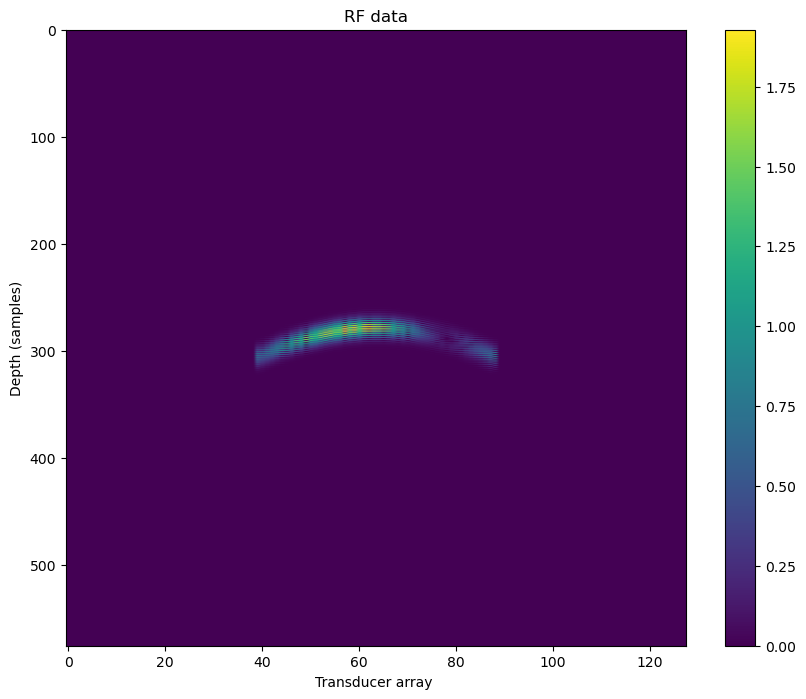

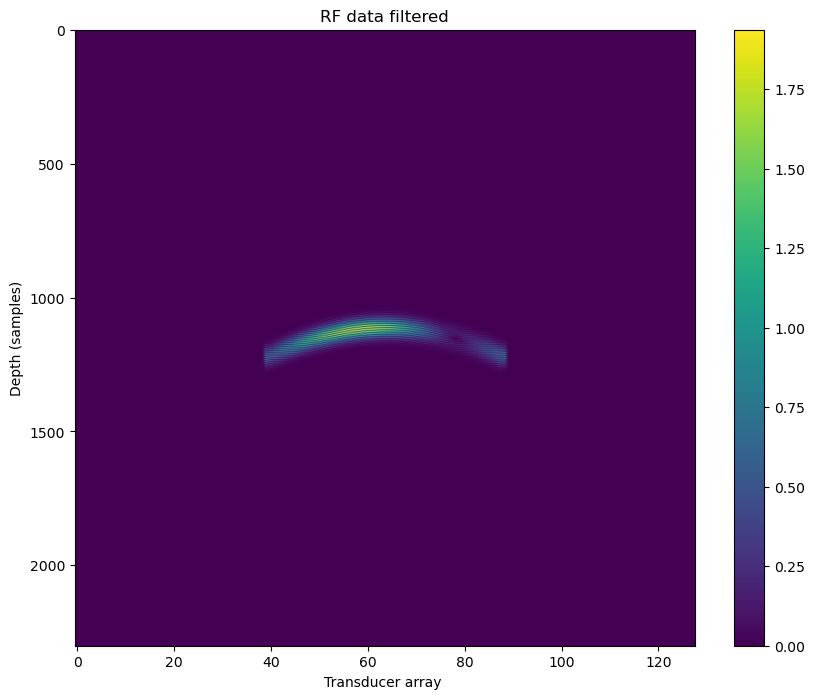

In [10]:
plt.figure(num=0, figsize=(10, 8))
plt.imshow(np.abs(rf[:,:,0]), cmap="viridis", aspect="auto")
plt.colorbar()
plt.title("RF data")
plt.xlabel("Transducer array ")
plt.ylabel("Depth (samples)")
plt.show()

plt.figure(num=1, figsize=(10, 8))
plt.imshow(np.abs(rff[:,:,0]), cmap="viridis", aspect="auto")
plt.colorbar()
plt.title("RF data filtered")
plt.xlabel("Transducer array ")
plt.ylabel("Depth (samples)")
plt.show()

# if apply_directional_filter:
#     plt.figure(num=2, figsize=(10, 8))
#     plt.imshow(np.abs(rff_up[:,:,0]), cmap="viridis", aspect="auto")
#     plt.colorbar()
#     plt.title("RF data filtered up")
#     plt.xlabel("Transducer array ")
#     plt.ylabel("Depth (samples)")
#     plt.show()
#     plt.figure(num=3, figsize=(10, 8))
#     plt.imshow(np.abs(rff_down[:,:,0]), cmap="viridis", aspect="auto")
#     plt.colorbar()
#     plt.title("RF data filtered down")
#     plt.xlabel("Transducer array ")
#     plt.ylabel("Depth (samples)")
#     plt.show()